# Modelado de tópicos con BERTopic: HDBSCAN frente a K-means

Bloque 2 (modelado de tópicos con BERTopic). Machine Learning 2026/27, competición de Kaggle *Contradictory, My Dear Watson*.

Este notebook calcula los embeddings de las premisas (guardados en caché) y ajusta dos pipelines de BERTopic que solo se diferencian en el algoritmo de clustering, HDBSCAN o K-means. Después los compara e interpreta, mira si los tópicos forman una jerarquía (tópicos y subtópicos), asigna tópico a las premisas de validación y estudia la relación de los tópicos con las clases NLI y con el idioma.

Datos que usa (ya están en el repositorio, generados en el Bloque 1):
- la partición train/val: `experiments/results/validation/historical_split/train.csv` y `val.csv`;
- el train oficial con premisa e hipótesis traducidas al inglés: `experiments/results/translation/corpus/train_gemma3_4b.csv`.

El modelo de embeddings se descarga de HuggingFace la primera vez que se ejecuta.

Para ejecutarlo, desde la raíz del repo y con el entorno virtual activado:

```
python -m jupyter nbconvert --to notebook --execute --inplace experiments/notebooks/topic_modeling.ipynb
```

Orden: primero `topic_eda.ipynb` y después `topic_modeling.ipynb`.
Semilla: `SEED = 42` en todo. Las versiones de los paquetes se imprimen en la primera celda de código.

In [1]:
import platform, importlib.metadata as md

SEED = 42  # semilla única para todo lo aleatorio (UMAP, K-means, muestras), así los resultados se repiten


def versiones(paquetes):
    """Devuelve (paquete, versión) para dejar constancia del entorno en el que se ejecutó el notebook."""
    filas = [("python", platform.python_version())]
    for p in paquetes:
        try:
            filas.append((p, md.version(p)))
        except md.PackageNotFoundError:
            filas.append((p, "no instalado"))
    return filas

import time, warnings, io, contextlib
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# Avisos de librerías que no afectan al resultado y ensucian la salida.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib as mpl
import matplotlib.pyplot as plt

# Colores fijos para que el mismo concepto tenga siempre el mismo color en todas las figuras.
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#8a5cd1", "#c23b3b"]
GRIS, GRIS_CLARO = "#8f8e88", "#d9d8d3"  # para "otros tópicos" y para los outliers
COLOR_CLASE = {"entailment": PALETA[0], "neutral": PALETA[1], "contradiction": PALETA[2]}

# Estilo sobrio: sin bordes superior/derecho y rejilla suave.
mpl.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})

pd.set_option("display.max_colwidth", 110)

for p, v in versiones(["bertopic", "umap-learn", "hdbscan", "sentence-transformers", "torch",
                       "scikit-learn", "scipy", "numpy", "pandas", "matplotlib"]):
    print(f"{p:22s} {v}")

python                 3.11.9
bertopic               0.17.4
umap-learn             0.6.0
hdbscan                0.8.44
sentence-transformers  6.3.0
torch                  2.15.0
scikit-learn           1.9.1
scipy                  1.17.1
numpy                  2.4.6
pandas                 3.1.1
matplotlib             3.11.2


## 0. Configuración

Todos los parámetros están en esta celda.

| Parámetro | Valor | Por qué |
|---|---|---|
| `TEXT_COL` | `premise_translated` | Texto traducido al inglés, como el mejor modelo con n-gramas del Bloque 1 (ver `topic_eda.ipynb`). |
| Embeddings | `paraphrase-multilingual-MiniLM-L12-v2` | El mismo modelo de frases que usa el Bloque 1. Da un vector de 384 números por frase. |
| UMAP | `n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine"` | Igual en las dos configuraciones, para que solo cambie el clustering. |
| A: HDBSCAN | `min_cluster_size` ∈ {15, 30, 50} | Rejilla pequeña. `prediction_data=True` permite asignar tópico a premisas nuevas. |
| B: K-means | `n_clusters=k`, `n_init=10` | k parecida al número de tópicos de A, con silhouette como comprobación. |
| c-TF-IDF | stopwords inglesas + {uh, um, yeah, oh}, unigramas y bigramas, `min_df=2` | Solo sirve para describir los tópicos con palabras; no cambia los grupos. |

In [2]:
TEXT_COL = "premise_translated"
MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
UMAP_PARAMS = dict(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED)
MCS_GRID = [15, 30, 50]                                   # valores de min_cluster_size que se prueban en HDBSCAN
OPT = {"dtype": {"id": str}, "keep_default_na": False}    # igual que en el Bloque 1


def raiz_repo():
    """Carpeta raíz del repositorio, para que el notebook funcione se abra desde donde se abra."""
    for carpeta in (Path.cwd(), *Path.cwd().parents):
        if (carpeta / "requirements.txt").is_file():
            return carpeta
    raise FileNotFoundError("Ejecuta el notebook dentro del repositorio.")


ROOT = raiz_repo()


def buscar(*rutas):
    """Primera ruta que exista. Los datos del Bloque 1 están en experiments/results/ (antes en artifacts/)."""
    for r in rutas:
        if (ROOT / r).exists():
            return ROOT / r
    raise FileNotFoundError(f"No se encuentra ninguna de estas rutas: {rutas}")


SPLITS = buscar("experiments/results/validation/historical_split", "artifacts/splits")
TRADUCCION = buscar("experiments/results/translation/corpus/train_gemma3_4b.csv",
                    "artifacts/translations/train_gemma3_4b.csv")

CACHE = ROOT / ".local" / "topics"                        # caché de embeddings (carpeta ignorada por git)
CACHE.mkdir(parents=True, exist_ok=True)
LABELS = {0: "entailment", 1: "neutral", 2: "contradiction"}


def corto(s, n):
    """Recorta un texto para que quepa en las etiquetas de las figuras."""
    return s if len(s) <= n else s[: n - 1] + "…"

## 1. Documentos y embeddings

### 1.1. Documentos: premisas sin repetir

Como se justifica en `topic_eda.ipynb`, un documento es una premisa distinta, deduplicada por su texto original (8.209 documentos). Para cada una se guarda el texto que se va a embeber (la primera traducción), su idioma original y si aparece en train, en val o en ambos.

In [3]:
# Filas con traducción + parte (train/val) de la partición del Bloque 1.
df = pd.read_csv(TRADUCCION, **OPT)
parts = pd.concat([pd.read_csv(SPLITS / "train.csv", **OPT)[["id"]].assign(part="train"),
                   pd.read_csv(SPLITS / "val.csv", **OPT)[["id"]].assign(part="val")])
df = df.merge(parts, on="id", validate="one_to_one")

# Una fila por premisa original (sort=False mantiene el orden del CSV, así el resultado es siempre el mismo).
g = df.groupby("premise", sort=False)
premises = pd.DataFrame({
    "premise_original": g.size().index,
    "text": g[TEXT_COL].first().values,                                   # primera traducción
    "lang_abv": g["lang_abv"].first().values,                             # idioma original
    "in_train": g["part"].apply(lambda s: s.eq("train").any()).values,
    "in_val": g["part"].apply(lambda s: s.eq("val").any()).values,
})


def frac_no_latina(s):
    """Fracción de letras no latinas; sirve para detectar premisas que se quedaron sin traducir."""
    letras = [c for c in s if c.isalpha()]
    return sum(ord(c) > 591 for c in letras) / max(1, len(letras))


# "Se lee en inglés": premisa inglesa de origen o traducción real. Solo se usa para elegir ejemplos legibles.
premises["texto_ingles"] = premises.lang_abv.eq("en") | (
    premises.text.ne(premises.premise_original) & premises.text.map(frac_no_latina).lt(0.3))

print(len(premises), "documentos |", int(premises.in_train.sum()), "en train |", int(premises.in_val.sum()), "en val |",
      int((premises.in_train & premises.in_val).sum()), "en ambos")

8209 documentos | 7051 en train | 2250 en val | 1092 en ambos


### 1.2. Modelo de embeddings

- `paraphrase-multilingual-MiniLM-L12-v2` es un modelo preentrenado de sentence-transformers. No lo entrenamos ni lo ajustamos: solo lo usamos para convertir cada premisa en un vector, de forma que frases con significado parecido tengan vectores cercanos. Es multilingüe: una frase y su traducción quedan casi en el mismo punto.
- **Entrenamiento previo con NLI:** los modelos `paraphrase-*` se entrenaron, entre otros datos, con AllNLI (SNLI + MultiNLI). Las premisas de esta competición vienen muy probablemente de XNLI (MultiNLI traducido a 15 idiomas), así que el modelo puede haber visto algunas de estas frases. Para los tópicos importa poco, porque no usamos etiquetas.
- **Lo que sí ajustamos nosotros**, y solo con train: UMAP, HDBSCAN o K-means y el vocabulario de c-TF-IDF.
- Calcular embeddings de val no es una fuga: el modelo no aprende nada de nuestros datos.
- `normalize_embeddings=True` deja cada vector con longitud 1, así el producto escalar es directamente la similitud coseno.
- Los embeddings tardan ~2 minutos en CPU. Se guardan en `.local/topics/` (ignorada por git) y las siguientes ejecuciones los cargan de ahí.

In [4]:
ruta_emb, ruta_docs = CACHE / "emb_premises.npy", CACHE / "premises.csv"

# Se reutiliza la caché solo si corresponde exactamente a los mismos documentos y en el mismo orden.
cache_ok = ruta_emb.exists() and ruta_docs.exists() and \
    pd.read_csv(ruta_docs, keep_default_na=False).premise_original.tolist() == premises.premise_original.tolist()

if cache_ok:
    emb = np.load(ruta_emb)
    print("Embeddings cargados de caché:", emb.shape)
else:
    from sentence_transformers import SentenceTransformer
    modelo_emb = SentenceTransformer(MODEL_NAME, device="cpu")
    t0 = time.perf_counter()
    emb = modelo_emb.encode(premises.text.tolist(), batch_size=64, normalize_embeddings=True,
                            show_progress_bar=False).astype(np.float32)
    print(f"Embeddings calculados en {time.perf_counter() - t0:.0f} s:", emb.shape)
    np.save(ruta_emb, emb)
    premises[["premise_original"]].to_csv(ruta_docs, index=False)

Embeddings cargados de caché: (8209, 384)


## 2. Qué hace BERTopic

1. **Embeddings:** cada premisa pasa a ser un vector de 384 números (sección 1).
2. **UMAP:** reduce esos 384 números a 5, intentando conservar qué documentos son vecinos. Los algoritmos de clustering funcionan mal con tantas dimensiones, porque todas las distancias acaban pareciéndose. `metric="cosine"` porque los embeddings se comparan por ángulo; `min_dist=0.0` deja que los puntos parecidos se junten mucho, lo que facilita encontrar grupos.
3. **Clustering** (el único paso que cambia entre A y B):
   - **A, HDBSCAN:** busca zonas densas. Decide él cuántos grupos hay, y lo que no cae en ninguna zona densa queda como outlier (tópico −1). `min_cluster_size` es el tamaño mínimo de un grupo.
   - **B, K-means:** hay que decirle k. Coloca k centros y asigna cada documento al más cercano, así que no hay outliers aunque un documento no encaje en ningún grupo.
4. **c-TF-IDF:** junta todos los documentos de un tópico como si fueran uno y busca las palabras frecuentes en ese tópico y raras en los demás. Son las palabras que describen el tópico.

Todo se ajusta solo con las 7.051 premisas de train.

In [5]:
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import silhouette_score, normalized_mutual_info_score as NMI
from bertopic import BERTopic

STOP = sorted(ENGLISH_STOP_WORDS | {"uh", "um", "yeah", "oh"})   # stopwords + muletillas del EDA


def nuevo_bertopic(clustering):
    """BERTopic con UMAP y c-TF-IDF fijos; solo cambia el algoritmo de clustering que se le pasa."""
    return BERTopic(
        embedding_model=None,                       # los embeddings se los damos ya calculados
        umap_model=UMAP(**UMAP_PARAMS),
        hdbscan_model=clustering,                   # el nombre del parámetro es histórico: acepta también K-means
        vectorizer_model=CountVectorizer(stop_words=STOP, ngram_range=(1, 2), min_df=2),
    )


# Datos de ajuste: solo premisas de train.
tr = premises[premises.in_train].reset_index(drop=True)
E_tr = emb[premises.in_train.values]
docs_tr, lang_tr = tr.text.tolist(), tr.lang_abv.values


def resumen(nombre, topics, modelo, segundos):
    """Métricas para comparar configuraciones (los outliers -1 no cuentan como tópico)."""
    t = np.asarray(topics)
    tam = pd.Series(t[t != -1]).value_counts()                         # tamaño de cada tópico
    palabras = [w for k in tam.index for w, _ in modelo.get_topic(k)[:10]]
    return {"configuracion": nombre, "n_topicos": int(tam.size),
            "pct_outliers": round(100 * np.mean(t == -1), 1),
            "tam_max": int(tam.max()), "tam_mediana": float(tam.median()), "tam_min": int(tam.min()),
            "diversidad_top10": round(len(set(palabras)) / len(palabras), 3),  # 1 = ningún tópico repite palabras
            "NMI_idioma": round(NMI(lang_tr, t), 3),                           # 0 = el tópico no dice nada del idioma
            "segundos": round(segundos, 1)}

## 3. Configuración A: HDBSCAN

Se prueban 3 valores de `min_cluster_size` con todo lo demás igual. Las métricas son el número de tópicos, el % de outliers, los tamaños, la diversidad de palabras (palabras distintas entre las 10 principales de todos los tópicos, dividido por el total) y la NMI con el idioma (0 si el tópico no tiene relación con el idioma, 1 si cada tópico es un idioma).

In [6]:
modelos_hdb, filas = {}, []
for mcs in MCS_GRID:
    t0 = time.perf_counter()
    modelo = nuevo_bertopic(HDBSCAN(min_cluster_size=mcs, prediction_data=True))
    topics, _ = modelo.fit_transform(docs_tr, E_tr)      # ajusta UMAP + HDBSCAN + c-TF-IDF
    modelos_hdb[mcs] = (modelo, np.asarray(topics))
    filas.append(resumen(f"A · HDBSCAN mcs={mcs}", topics, modelo, time.perf_counter() - t0))
display(pd.DataFrame(filas))

,configuracion,n_topicos,pct_outliers,tam_max,tam_mediana,tam_min,diversidad_top10,NMI_idioma,segundos
0,A · HDBSCAN mcs=15,55,38.2,788,42.0,16,0.940,0.048,42.6
1,A · HDBSCAN mcs=30,20,30.9,1762,107.0,34,0.895,0.026,9.0
2,A · HDBSCAN mcs=50,19,44.8,851,169.0,53,0.921,0.027,9.1


Elegimos `min_cluster_size = 30`.

- Con 15 salen unos 55 tópicos muy pequeños, demasiados para interpretarlos, y un 38 % de outliers.
- Con 50 los tópicos son muy limpios, pero casi la mitad de las premisas (45 %) se queda sin tópico.
- Con 30 hay unos 20 tópicos, un número manejable, y el menor % de outliers (31 %). Su punto débil es un tópico grande (~25 % de los documentos) que reúne todos los informes oficiales.

Se usa el modelo ya ajustado en la rejilla.

In [7]:
MCS = 30
tm_hdb, top_hdb = modelos_hdb[MCS]
reducido = tm_hdb.umap_model.embedding_   # las premisas de train ya reducidas a 5 dimensiones por UMAP
print("Tópicos:", len(set(top_hdb) - {-1}), "| outliers:", int((top_hdb == -1).sum()))

Tópicos: 20 | outliers: 2182


## 4. Configuración B: K-means

K-means necesita k. Como comprobación se calcula la silhouette (de −1 a 1; más alta = grupos mejor separados) para unos pocos valores de k, sobre la misma reducción UMAP.

In [8]:
sil = []
for k in [10, 15, 20, 25, 30, 40]:
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(reducido)
    sil.append({"k": k, "silhouette": round(silhouette_score(reducido, etiquetas), 3)})
display(pd.DataFrame(sil))

,k,silhouette
0,10,0.343
1,15,0.364
2,20,0.347
3,25,0.355
4,30,0.354
5,40,0.365


Elegimos k = 20. La silhouette es casi igual para todos los k probados (entre 0,34 y 0,37), así que no marca ninguno como claramente mejor. Usamos el mismo número de tópicos que A: así las dos configuraciones describen el corpus con el mismo nivel de detalle y la comparación se centra en cómo agrupa cada algoritmo.

In [9]:
K = len(set(top_hdb) - {-1})   # mismo número de tópicos que HDBSCAN
t0 = time.perf_counter()
tm_km = nuevo_bertopic(KMeans(n_clusters=K, n_init=10, random_state=SEED))
top_km = np.asarray(tm_km.fit_transform(docs_tr, E_tr)[0])
seg_km = time.perf_counter() - t0

comparacion = pd.DataFrame([f for f in filas if f["configuracion"].endswith(f"={MCS}")] +
                           [resumen(f"B · K-means k={K}", top_km, tm_km, seg_km)])
display(comparacion)

,configuracion,n_topicos,pct_outliers,tam_max,tam_mediana,tam_min,diversidad_top10,NMI_idioma,segundos
0,A · HDBSCAN mcs=30,20,30.9,1762,107.0,34,0.895,0.026,9.0
1,B · K-means k=20,20,0.0,701,349.5,171,0.820,0.021,9.0


## 5. Los tópicos: palabras, documentos representativos y nombres

Para cada tópico se muestran las 10 palabras con más peso en c-TF-IDF, 3 documentos representativos y un nombre que hemos puesto a mano después de leer palabras y documentos. Los documentos representativos son las premisas más cercanas al centro del tópico (similitud coseno); se eligen entre las que se leen en inglés.

Los números de tópico son solo identificadores: BERTopic los ordena por tamaño (0 es el más grande), y el tópico 3 de A no tiene nada que ver con el tópico 3 de B.

In [10]:
NOMBRES_HDB = {
    -1: "Outliers (sin tópico)", 0: "Gobierno: servicios legales, programas y costes", 1: "Viajes: ciudades, playas y monumentos",
    2: "Ficción histórica (Lord Julian, capitán Blood)", 3: "Conversación: asentimientos (that's good, yes)",
    4: "Conversación: clima y vida en Texas", 5: "Informe del 11-S (KSM, CIA, FDNY)", 6: "Ficción: personajes y diálogo",
    7: "Hijos y crianza", 8: "Prensa y libros (Slate, NYT)", 9: "Negación: no sé / no recuerdo", 10: "Aviación y pilotos",
    11: "Lengua y palabras", 12: "Texto sin traducir (suajili / hindi-urdu)", 13: "Comida",
    14: "Ordenadores y tecnología", 15: "Clinton y la Casa Blanca", 16: "Deportes", 17: "Cultura hispana del suroeste de EE. UU.",
    18: "Plazos y tiempo de espera", 19: "Música",
}
NOMBRES_KM = {
    0: "Gestión pública y agencias", 1: "Ficción histórica (Lord Julian, capitán Blood)", 2: "Costes, correo postal e impuestos",
    3: "Viajes: playas, islas y tiendas", 4: "Conversación: asentimientos", 5: "Mezcla: frases cortas sin tema",
    6: "Mezcla: ciencia, ordenadores y frases sueltas", 7: "Negación: no sé / no creo", 8: "Monumentos: templos, iglesias, historia",
    9: "Servicios legales y universidades", 10: "Conversación: clima y Texas", 11: "Texto sin traducir (suajili / hindi-urdu)",
    12: "Informe del 11-S", 13: "Prensa, libros y Clinton", 14: "Derechos y política", 15: "Ficción: personajes femeninos",
    16: "Hijos y escuela", 17: "Lengua y palabras", 18: "Arte, música y museos", 19: "Aviación y combate",
}


def tabla_topicos(modelo, topics, nombres):
    """Una fila por tópico: nombre, tamaño, 10 palabras clave y 3 documentos representativos."""
    filas = []
    for k in sorted(set(topics)):
        idx = np.where(topics == k)[0]                     # documentos del tópico
        centro = E_tr[idx].mean(0)
        centro /= np.linalg.norm(centro)
        orden = idx[np.argsort(-(E_tr[idx] @ centro))]     # del más parecido al centro al menos parecido
        ejemplos = [docs_tr[i] for i in orden if tr.texto_ingles[i]][:3]
        filas.append({"topic": k, "nombre": nombres[k], "n_docs": len(idx),
                      "top10": ", ".join(w for w, _ in modelo.get_topic(k)[:10]),
                      "ejemplos": ejemplos})
    return pd.DataFrame(filas)


tab_hdb = tabla_topicos(tm_hdb, top_hdb, NOMBRES_HDB)
tab_km = tabla_topicos(tm_km, top_km, NOMBRES_KM)
with pd.option_context("display.max_colwidth", 90):
    print("A · HDBSCAN"); display(tab_hdb[["topic", "nombre", "n_docs", "top10"]])
    print("B · K-means"); display(tab_km[["topic", "nombre", "n_docs", "top10"]])

A · HDBSCAN


,topic,nombre,n_docs,top10
0,-1,Outliers (sin tópico),2182,"know, like, time, dont, just, think, people, said, did, really"
1,0,"Gobierno: servicios legales, programas y costes",1762,"legal, services, information, state, new, programs, federal, money, help, cost"
2,1,"Viajes: ciudades, playas y monumentos",859,"city, square, built, island, museum, beach, located, art, river, west"
3,2,"Ficción histórica (Lord Julian, capitán Blood)",287,"julian, lord, blood, bishop, voice, captain, ogle, said, er, pitt"
4,3,"Conversación: asentimientos (that's good, yes)",254,"thats, good, like, think, yes, uhhuh, im, right, say, ill"
5,4,Conversación: clima y vida en Texas,236,"know, texas, really, summer, like, weather, dont, hot, just, yes"
6,5,"Informe del 11-S (KSM, CIA, FDNY)",236,"ksm, september, 2001, fdny, cia, york, new york, intelligence, police, tower"
7,6,Ficción: personajes y diálogo,193,"girl, said, eyes, mrs, voice, shes, wife, hair, know, ella"
8,7,Hijos y crianza,179,"children, kids, parents, know, old, mother, age, theyre, dont, just"
9,8,"Prensa y libros (Slate, NYT)",122,"book, times, read, slate, new, new york, york, york times, news, newspaper"


B · K-means


,topic,nombre,n_docs,top10
0,0,Gestión pública y agencias,701,"information, management, requirements, agencies, federal, data, financial, organizatio..."
1,1,"Ficción histórica (Lord Julian, capitán Blood)",516,"blood, jon, said, julian, hes, lord, bishop, tommy, captain, voice"
2,2,"Costes, correo postal e impuestos",448,"cost, postal, money, saving, costs, mail, volume, tax, income, assets"
3,3,"Viajes: playas, islas y tiendas",436,"city, beach, island, islands, shops, located, known, street, miles, restaurants"
4,4,Conversación: asentimientos,424,"thats, know, good, like, right, im, really, think, yes, just"
5,5,Mezcla: frases cortas sin tema,420,"like, said, im, went, ti, time, know, today, dont, think"
6,6,"Mezcla: ciencia, ordenadores y frases sueltas",401,"know, time, like, months, computer, just, think, molecular, need, scr"
7,7,Negación: no sé / no creo,386,"dont, know, think, didnt, dont know, really, khng, dont think, like, ti"
8,8,"Monumentos: templos, iglesias, historia",360,"built, church, temple, city, house, bc, roman, square, century, ii"
9,9,Servicios legales y universidades,350,"legal, services, university, legal services, help, justice, program, school, support, law"


### 5.1. Documentos representativos (3 por tópico)

In [11]:
for titulo, tab in [("A · HDBSCAN", tab_hdb), ("B · K-means", tab_km)]:
    print(f"===== {titulo} =====")
    for _, fila in tab.iterrows():
        print(f"[{fila.topic}] {fila.nombre} (n={fila.n_docs})")
        for texto in fila.ejemplos:
            print("     -", texto[:140])
    print()

===== A · HDBSCAN =====
[-1] Outliers (sin tópico) (n=2182)
     - Oh, kumbe yako ni ya milango minne.
     - Um, as far as I was ever told--
     - yeah well we veered from the subject
[0] Gobierno: servicios legales, programas y costes (n=1762)
     - Tabulations of actual meetings and of consequent actions for same-agency funded and different-agency funded services can help check out whet
     - Comparing our experience on the Acid Rain Program with the NOx SIP Call and the Section 126 petitions demonstrates the benefit of having cer
     - In addition, because funding is secured on an
[1] Viajes: ciudades, playas y monumentos (n=859)
     - Keep your eyes open for Renaissance details, grand doorways, and views into lovely courtyards.
     - Off El Hurriya Street you'll find the Neo-Classical facade of the Greco-Roman Museum with a fine collection of both Roman, Greek, and Ptolem
     - You can eat and shop in and around the once-magnificent and heavily fortified Crusader city, with

### 5.2. Comentario de tópicos

Los tópicos coinciden casi exactamente con los géneros de MultiNLI, de donde viene XNLI: informes del gobierno, guías de viaje, ficción, conversaciones telefónicas, la revista Slate y el informe de la Comisión del 11-S.

A · HDBSCAN (mcs = 30)
- **T0, Gobierno (~1.760 documentos, el 25 %):** *legal, services, information, state, federal, programs, cost*. Son informes de financiación y programas de agencias. Es demasiado grande: HDBSCAN no encuentra zonas menos densas dentro de este bloque que le permitan partirlo. Es el principal defecto de A.
- **T5, Informe del 11-S:** *ksm, september, 2001, fdny, cia, intelligence*. Son notas al pie del informe ("see intelligence report, KSM interrogation…"). Es un tópico muy nítido, con un vocabulario muy específico.
- **T3, T4, T9 y T18, Conversaciones telefónicas:** asentimientos (*that's good, yes, uh-huh*), charla sobre el clima de Texas, negaciones (*don't know, don't remember*) y plazos.
- **T12, Texto sin traducir:** *ya, na, wa, kwa, hai, aur, ke* son palabras funcionales del suajili y del hindi/urdu escrito con letras latinas. Es el único tópico que agrupa por idioma y no por tema, y viene de las premisas que no se tradujeron.
- **Outliers (−1, 31 %):** palabras genéricas (*know, like, time, don't, just, think*). Son sobre todo frases cortas o conversacionales sin un tema claro.

B · K-means (k = 20)
- **T0, T2, T9 y T14, Gobierno partido en cuatro:** gestión de agencias; costes, correo e impuestos; servicios legales; derechos y política. Como K-means no depende de la densidad, parte las regiones grandes en trozos de tamaño parecido.
- **T5, T6 y T7, Grupos "cajón de sastre":** K-means no puede dejar documentos fuera, así que lo que HDBSCAN marcaba como outlier acaba en grupos con palabras genéricas (*like, said, I'm, went, time*) y sin un tema común.
- **T12, Informe del 11-S:** sale igual que en A. Los temas con vocabulario propio aparecen con los dos algoritmos, lo que indica que son temas reales.
- **T11, Texto sin traducir:** también aparece, y más grande (~295 documentos frente a 81 en A).

## 6. Visualizaciones

### 6.1. Tamaño de los tópicos

En A, la barra gris es el tópico −1 (outliers). B no tiene outliers.

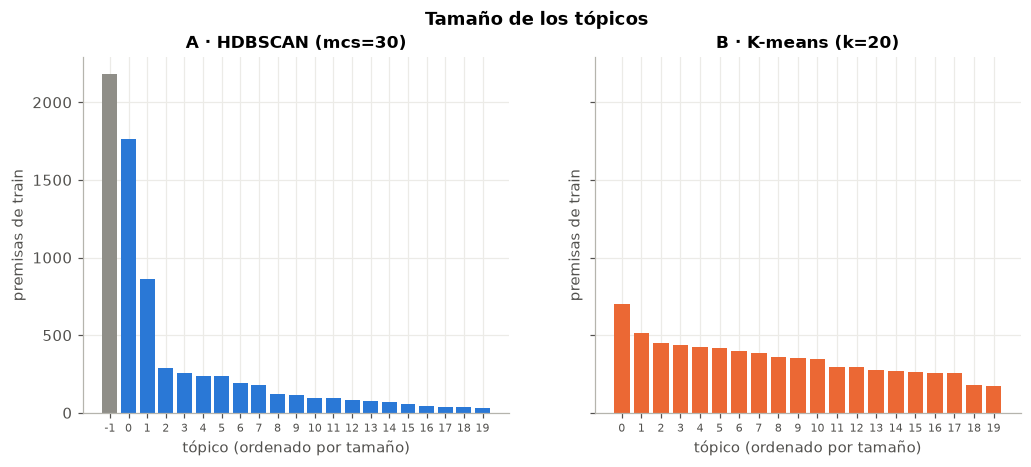

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, top, titulo, color in [(axes[0], top_hdb, f"A · HDBSCAN (mcs={MCS})", PALETA[0]),
                               (axes[1], top_km, f"B · K-means (k={K})", PALETA[1])]:
    tamanos = pd.Series(top).value_counts()
    orden = ([-1] if -1 in tamanos.index else []) + [k for k in tamanos.index if k != -1]  # outliers primero
    ax.bar(range(len(orden)), tamanos[orden].values, color=[GRIS if k == -1 else color for k in orden], width=0.8)
    ax.set_xticks(range(len(orden)), [str(k) for k in orden], fontsize=7)
    ax.set_title(titulo); ax.set_xlabel("tópico (ordenado por tamaño)"); ax.set_ylabel("premisas de train")
fig.suptitle("Tamaño de los tópicos", fontweight="bold")
plt.show()

### 6.2. Palabras principales de los 8 tópicos más grandes

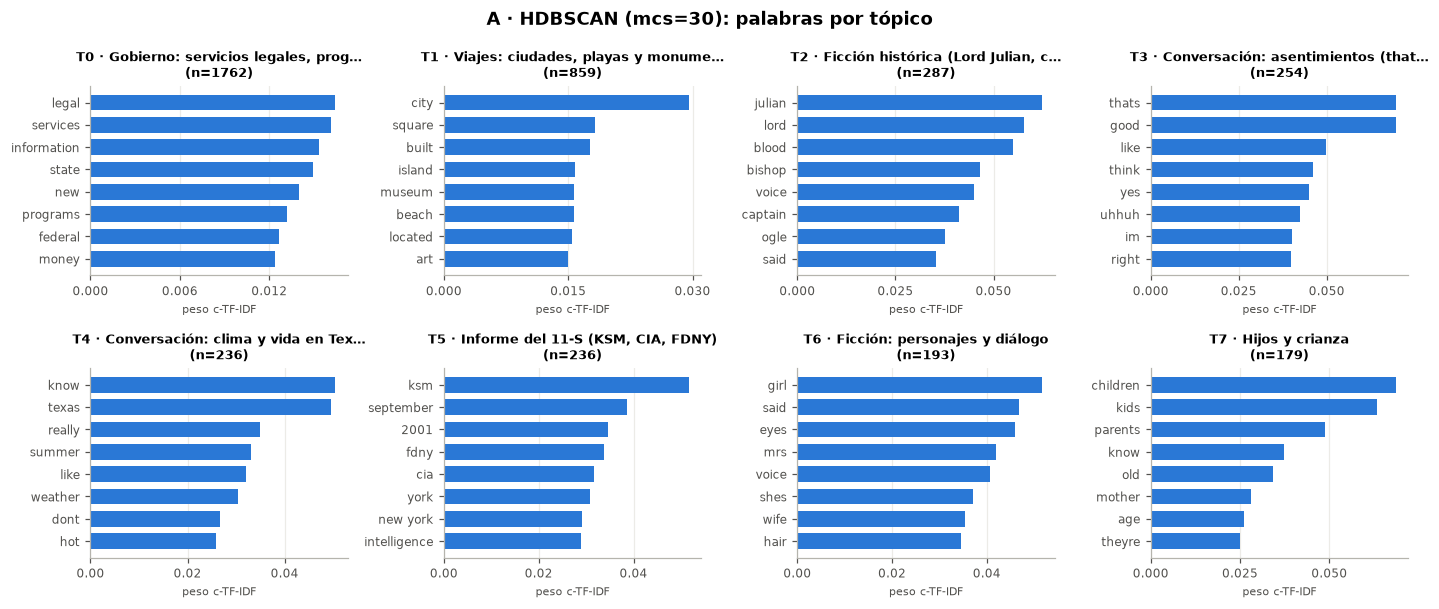

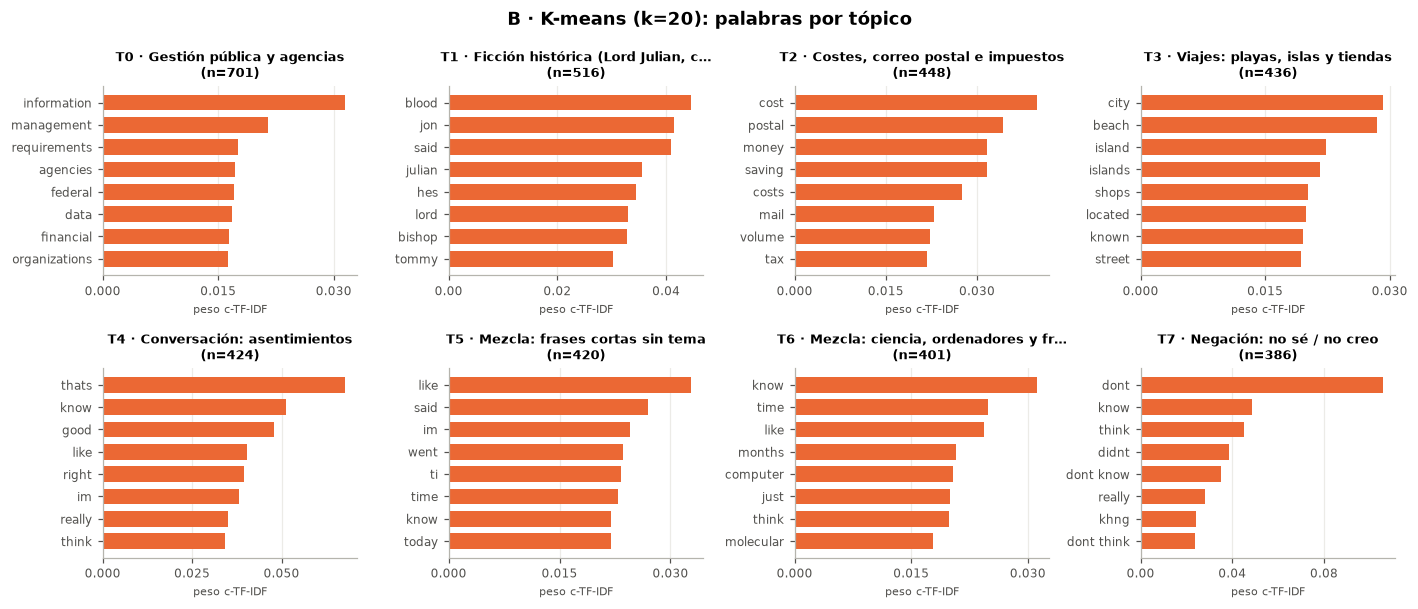

In [13]:
def barras_palabras(modelo, top, nombres, titulo, color):
    """Un panel por tópico con sus 8 palabras de más peso en c-TF-IDF."""
    tamanos = pd.Series(top).value_counts()
    grandes = [k for k in tamanos.index if k != -1][:8]
    fig, axes = plt.subplots(2, 4, figsize=(13, 5.6))
    for ax, k in zip(axes.flat, grandes):
        palabras = modelo.get_topic(k)[:8][::-1]          # al revés para que la más importante quede arriba
        ax.barh([w for w, _ in palabras], [s for _, s in palabras], color=color, height=0.7)
        ax.set_title(f"T{k} · {corto(nombres[k], 34)}\n(n={tamanos[k]})", fontsize=8.5)
        ax.tick_params(labelsize=8); ax.grid(axis="y", visible=False)
        ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(3))
        ax.set_xlabel("peso c-TF-IDF", fontsize=7.5)
    fig.suptitle(titulo, fontweight="bold"); fig.tight_layout()
    plt.show()


barras_palabras(tm_hdb, top_hdb, NOMBRES_HDB, f"A · HDBSCAN (mcs={MCS}): palabras por tópico", PALETA[0])
barras_palabras(tm_km, top_km, NOMBRES_KM, f"B · K-means (k={K}): palabras por tópico", PALETA[1])

### 6.3. Mapa 2D de los documentos

Para poder dibujarlos, los embeddings de train se reducen a 2 dimensiones con UMAP (mismos parámetros, pero `n_components=2`). Esta reducción solo sirve para la figura; el clustering se hizo en 5 dimensiones. Se colorean los 8 tópicos más grandes; el resto va en gris y los outliers en gris claro.

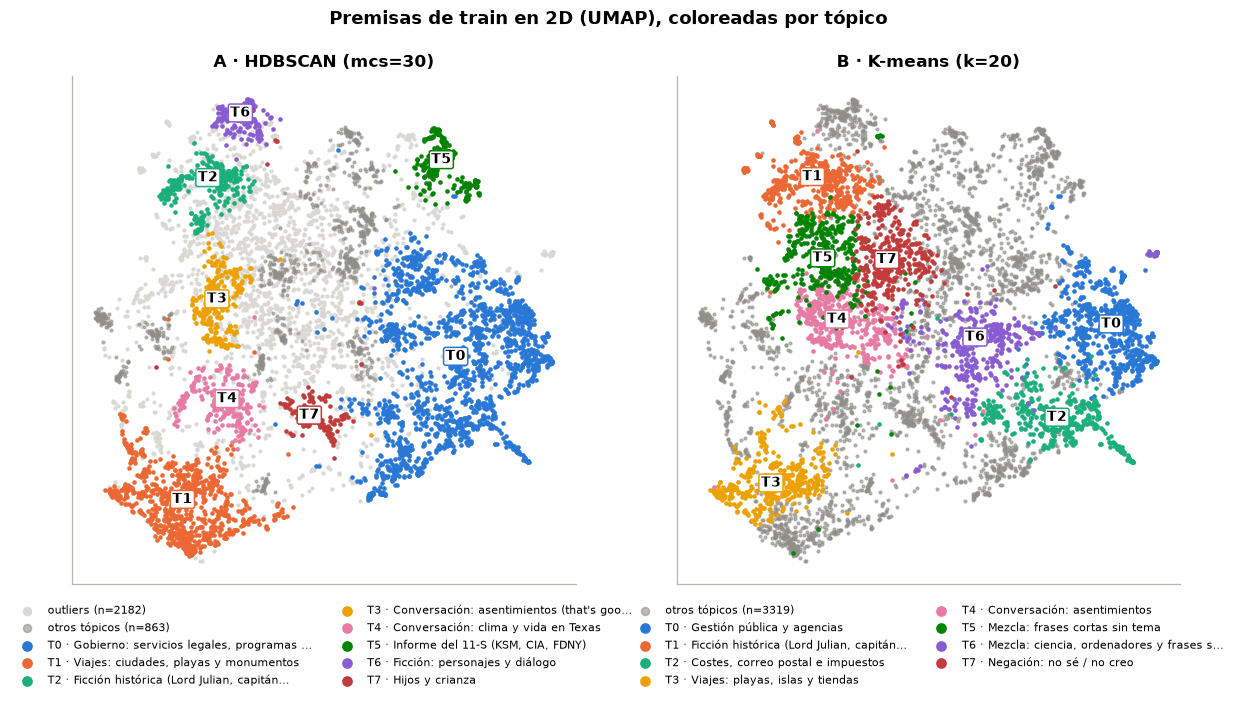

In [14]:
xy = UMAP(**{**UMAP_PARAMS, "n_components": 2}).fit_transform(E_tr)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, top, nombres, titulo in [(axes[0], top_hdb, NOMBRES_HDB, f"A · HDBSCAN (mcs={MCS})"),
                                 (axes[1], top_km, NOMBRES_KM, f"B · K-means (k={K})")]:
    tamanos = pd.Series(top).value_counts()
    grandes = [k for k in tamanos.index if k != -1][:8]
    es_outlier = top == -1
    es_resto = ~np.isin(top, grandes) & ~es_outlier
    if es_outlier.any():
        ax.scatter(*xy[es_outlier].T, s=3, c=GRIS_CLARO, label=f"outliers (n={es_outlier.sum()})", rasterized=True)
    ax.scatter(*xy[es_resto].T, s=3, c=GRIS, alpha=0.6, label=f"otros tópicos (n={es_resto.sum()})", rasterized=True)
    for color, k in zip(PALETA, grandes):
        sel = top == k
        ax.scatter(*xy[sel].T, s=4, c=color, label=f"T{k} · {corto(nombres[k], 40)}", rasterized=True)
        cx, cy = np.median(xy[sel], axis=0)               # etiqueta con el número del tópico en su centro
        ax.text(cx, cy, f"T{k}", fontsize=9, fontweight="bold", ha="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec=color, lw=1))
    ax.set_title(titulo); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, fontsize=7.5, markerscale=3)
fig.suptitle("Premisas de train en 2D (UMAP), coloreadas por tópico", fontweight="bold")
plt.show()

### 6.4. Comparación de los dos pipelines

| Aspecto | A · HDBSCAN | B · K-means |
|---|---|---|
| Número de tópicos | Lo decide el algoritmo (20 con mcs=30) | Lo fijamos nosotros (k=20) |
| Outliers | ~31 % en −1 | Ninguno: todo documento recibe tópico |
| Tamaños | Muy desiguales (de 34 a 1.762) | Más parecidos (de 171 a 701) |
| Diversidad de palabras | 0,895 | 0,820: más palabras repetidas entre grupos conversacionales |
| Interpretabilidad | Tópicos pequeños muy claros; un tópico "gobierno" demasiado grande | Gobierno bien partido en 4; 2–3 grupos sin tema |
| Idioma (NMI) | ≈0,03 | ≈0,02 |

A es mejor para interpretar, porque deja aparte lo que no encaja en vez de mezclarlo. B asigna un tópico a todo, a costa de crear algunos grupos sin sentido. Los temas con vocabulario propio (11-S, ficción histórica, lengua, texto sin traducir) salen en los dos.

## 7. ¿Hay jerarquía? Tópicos y subtópicos

Se mira de dos formas.

1. **Árbol de tópicos de HDBSCAN.** `hierarchical_topics` de BERTopic compara los tópicos por sus palabras (vectores c-TF-IDF) y los va uniendo de dos en dos, empezando por los más parecidos (clustering jerárquico de Ward). El resultado es un árbol: si tópicos con temas relacionados se unen pronto, hay estructura de "supertópicos".
2. **Tópicos de HDBSCAN repartidos en los de K-means.** Si un tópico grande de HDBSCAN se reparte entre varios tópicos de K-means con temas más concretos, esos son sus subtópicos.

In [15]:
# hierarchical_topics muestra una barra de progreso; se silencia para que la salida quede limpia.
with contextlib.redirect_stderr(io.StringIO()):
    jerarquia = tm_hdb.hierarchical_topics(docs_tr)
print(tm_hdb.get_topic_tree(jerarquia))

.
├─know_dont_like_think_really
│    ├─know_dont_like_think_thats
│    │    ├─■──milk_food_snake_lunch_eat ── Topic: 13
│    │    └─know_dont_like_think_thats
│    │         ├─know_dont_like_think_really
│    │         │    ├─■──computer_like_mit_emulate_digital ── Topic: 14
│    │         │    └─know_dont_like_think_thats
│    │         │         ├─dont_children_know_kids_parents
│    │         │         │    ├─■──dont_dont know_know_think_dont remember ── Topic: 9
│    │         │         │    └─■──children_kids_parents_know_old ── Topic: 7
│    │         │         └─know_like_thats_texas_yes
│    │         │              ├─know_like_thats_texas_really
│    │         │              │    ├─■──thats_good_like_think_yes ── Topic: 3
│    │         │              │    └─■──know_texas_really_summer_like ── Topic: 4
│    │         │              └─■──minutes_know_make sure_weeks_okay ── Topic: 18
│    │         └─■──team_football_theyre_sports_league ── Topic: 16
│    └─voice_said_julian_lo

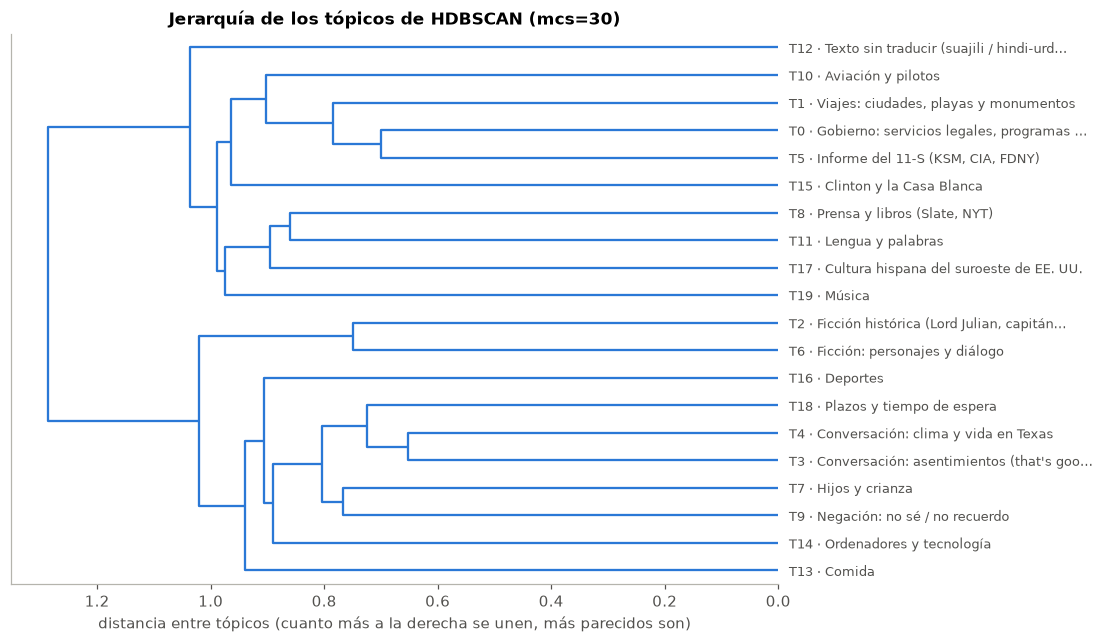

In [16]:
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from sklearn.metrics.pairwise import cosine_similarity

# Mismo cálculo que hace hierarchical_topics, pero dibujado con los nombres de los tópicos.
ids = sorted(set(top_hdb) - {-1})
ctfidf = tm_hdb.c_tf_idf_[1:]                        # la fila 0 corresponde a los outliers (-1)
dist = 1 - cosine_similarity(ctfidf)                 # distancia = 1 - similitud entre tópicos
np.fill_diagonal(dist, 0)
Z = linkage(squareform(dist, checks=False), method="ward", optimal_ordering=True)

fig, ax = plt.subplots(figsize=(9, 6.5))
dendrogram(Z, orientation="left", labels=[f"T{k} · {corto(NOMBRES_HDB[k], 40)}" for k in ids],
           color_threshold=0, above_threshold_color=PALETA[0], ax=ax)
ax.set_xlabel("distancia entre tópicos (cuanto más a la derecha se unen, más parecidos son)")
ax.grid(False); ax.tick_params(axis="y", labelsize=8.5)
ax.set_title(f"Jerarquía de los tópicos de HDBSCAN (mcs={MCS})")
plt.show()

In [17]:
# Para cada uno de los tópicos más grandes de HDBSCAN: en qué tópicos de K-means caen sus documentos.
cruce = pd.crosstab(top_hdb, top_km)
for k in [0, 1, 2, -1]:
    reparto = cruce.loc[k][cruce.loc[k] > 0].sort_values(ascending=False)
    reparto = (100 * reparto / reparto.sum()).round(0).head(5)
    detalle = ", ".join(f"{NOMBRES_KM[j]} {p:.0f} %" for j, p in reparto.items())
    print(f"HDBSCAN T{k} · {NOMBRES_HDB[k]} (n={cruce.loc[k].sum()}):\n    {detalle}")

HDBSCAN T0 · Gobierno: servicios legales, programas y costes (n=1762):
    Gestión pública y agencias 36 %, Costes, correo postal e impuestos 25 %, Servicios legales y universidades 18 %, Derechos y política 13 %, Mezcla: ciencia, ordenadores y frases sueltas 8 %
HDBSCAN T1 · Viajes: ciudades, playas y monumentos (n=859):
    Viajes: playas, islas y tiendas 44 %, Monumentos: templos, iglesias, historia 41 %, Arte, música y museos 14 %, Texto sin traducir (suajili / hindi-urdu) 1 %
HDBSCAN T2 · Ficción histórica (Lord Julian, capitán Blood) (n=287):
    Ficción histórica (Lord Julian, capitán Blood) 90 %, Mezcla: frases cortas sin tema 10 %
HDBSCAN T-1 · Outliers (sin tópico) (n=2182):
    Mezcla: frases cortas sin tema 14 %, Negación: no sé / no creo 12 %, Ficción histórica (Lord Julian, capitán Blood) 12 %, Conversación: asentimientos 9 %, Mezcla: ciencia, ordenadores y frases sueltas 8 %


Sí hay jerarquía, y tiene sentido:
- **Primer corte del árbol:** separa el texto oral y narrativo (conversaciones telefónicas, ficción, hijos, deportes) del texto escrito e informativo (gobierno, 11-S, viajes, prensa, lengua, música). Es la diferencia de registro entre los géneros de MultiNLI.
- **Supertópicos dentro de cada rama:** las dos ficciones (T2 y T6) se unen entre sí; las conversaciones (asentimientos, clima en Texas, plazos) forman un bloque; gobierno (T0) se une primero con el 11-S (T5), también un informe oficial; prensa, lengua, cultura hispana y música forman otro bloque.
- **Subtópicos:** el tópico grande de HDBSCAN "Gobierno" se reparte sobre todo en cuatro tópicos de K-means (gestión pública, costes/correo/impuestos, servicios legales, derechos y política), y "Viajes" en playas, monumentos y arte. Son sus subtópicos. HDBSCAN no los separa porque no hay huecos de densidad entre ellos, pero los temas están ahí.
- **Texto sin traducir (T12)** es el último en unirse a su rama, como era de esperar: lo que tiene en común es el idioma, no el tema.

## 8. Tópico de las premisas de validación (`transform`)

Las 2.250 premisas de val pasan por `transform`, como haría el modelo con datos nuevos: el embedding se reduce con el UMAP ya ajustado y después se asigna con HDBSCAN (`approximate_predict`) o con K-means (centro más cercano). Nada se vuelve a ajustar con val, así que no hay fuga. Las filas de train usan el tópico que les dio el ajuste.

Como comprobación, para las 1.092 premisas que están en train y en val se mira si `transform` les da el mismo tópico que el ajuste.

In [18]:
val_p = premises[premises.in_val].reset_index(drop=True)
E_v = emb[premises.in_val.values]
tv_hdb = np.asarray(tm_hdb.transform(val_p.text.tolist(), E_v)[0])
tv_km = np.asarray(tm_km.transform(val_p.text.tolist(), E_v)[0])

# Tópico de cada premisa, en train (fit) y en val (transform).
mapa_tr = pd.DataFrame({"premise": tr.premise_original, "topic_hdb": top_hdb, "topic_km": top_km})
mapa_va = pd.DataFrame({"premise": val_p.premise_original, "topic_hdb": tv_hdb, "topic_km": tv_km})

# Cada fila hereda el tópico de su premisa, según la parte en la que está.
base = df[["id", "part", "premise", "label", "lang_abv"]]
rows = pd.concat([base[base.part == "train"].merge(mapa_tr, on="premise", how="left"),
                  base[base.part == "val"].merge(mapa_va, on="premise", how="left")], ignore_index=True)
assert rows[["topic_hdb", "topic_km"]].notna().all().all()

comp = mapa_va.merge(mapa_tr, on="premise", suffixes=("_val", "_train"))
print(f"Premisas en train y val: {len(comp)} | mismo tópico con transform que con fit: "
      f"HDBSCAN {np.mean(comp.topic_hdb_val == comp.topic_hdb_train):.1%}, "
      f"K-means {np.mean(comp.topic_km_val == comp.topic_km_train):.1%}")
print(f"Outliers de HDBSCAN: train {np.mean(top_hdb == -1):.1%} | val {np.mean(tv_hdb == -1):.1%}")

Premisas en train y val: 1092 | mismo tópico con transform que con fit: HDBSCAN 94.1%, K-means 96.7%
Outliers de HDBSCAN: train 30.9% | val 34.9%


## 9. Tópicos frente a clases NLI

Los tópicos describen de qué habla la premisa. No son las clases NLI: la clase depende de la relación entre premisa e hipótesis, y cada premisa aparece con hipótesis de clases distintas. Por eso esperamos poca relación entre tópico y clase.

Se cruza el tópico de cada fila de train (9.696 pares) con su clase. Se calcula el chi-cuadrado (¿la mezcla de clases es la misma en todos los tópicos?) y la V de Cramér (fuerza de la relación, de 0 a 1; por debajo de 0,1 es despreciable). Las filas de una misma premisa comparten tópico y no son del todo independientes, así que el p-valor es algo optimista; la V de Cramér es la medida importante.

In [19]:
from scipy.stats import chi2_contingency

filas_train = rows[rows.part == "train"].assign(clase=lambda d: d.label.map(LABELS))


def topicos_vs_clase(col, nombres):
    """Tabla tópico x clase (n y %) más chi-cuadrado y V de Cramér."""
    ct = pd.crosstab(filas_train[col], filas_train.clase).reindex(columns=list(LABELS.values()))
    chi2, p, gl, _ = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    tabla = pd.concat([ct.sum(axis=1).rename("n"), (ct.div(ct.sum(axis=1), axis=0) * 100).round(1).add_suffix(" %")], axis=1)
    tabla.insert(0, "nombre", [nombres[k] for k in tabla.index])
    return tabla, {"chi2": round(float(chi2), 1), "gl": int(gl), "p": round(float(p), 3), "V_Cramer": round(float(v), 3)}


tc_hdb, est_hdb = topicos_vs_clase("topic_hdb", NOMBRES_HDB)
tc_km, est_km = topicos_vs_clase("topic_km", NOMBRES_KM)
print("A · HDBSCAN:", est_hdb); display(tc_hdb)
print("B · K-means:", est_km); display(tc_km)

A · HDBSCAN: {'chi2': 40.0, 'gl': 40, 'p': 0.469, 'V_Cramer': 0.045}


,nombre,n,entailment %,neutral %,contradiction %
topic_hdb,,,,,
-1,Outliers (sin tópico),2994,33.9,32.3,33.8
0,"Gobierno: servicios legales, programas y costes",2423,34.8,32.4,32.8
1,"Viajes: ciudades, playas y monumentos",1267,36.7,31.1,32.2
2,"Ficción histórica (Lord Julian, capitán Blood)",382,31.7,32.7,35.6
3,"Conversación: asentimientos (that's good, yes)",371,37.7,28.8,33.4
4,Conversación: clima y vida en Texas,334,36.5,28.1,35.3
5,"Informe del 11-S (KSM, CIA, FDNY)",265,33.6,32.5,34.0
6,Ficción: personajes y diálogo,268,32.8,32.1,35.1
7,Hijos y crianza,239,31.4,34.7,33.9


B · K-means: {'chi2': 30.3, 'gl': 38, 'p': 0.807, 'V_Cramer': 0.04}


,nombre,n,entailment %,neutral %,contradiction %
topic_km,,,,,
0,Gestión pública y agencias,994,37.5,29.9,32.6
1,"Ficción histórica (Lord Julian, capitán Blood)",758,34.0,32.3,33.6
2,"Costes, correo postal e impuestos",650,35.4,31.2,33.4
3,"Viajes: playas, islas y tiendas",633,35.7,31.1,33.2
4,Conversación: asentimientos,639,36.5,30.4,33.2
5,Mezcla: frases cortas sin tema,568,32.0,32.9,35.0
6,"Mezcla: ciencia, ordenadores y frases sueltas",504,31.3,33.5,35.1
7,Negación: no sé / no creo,538,32.0,32.5,35.5
8,"Monumentos: templos, iglesias, historia",558,36.7,32.4,30.8


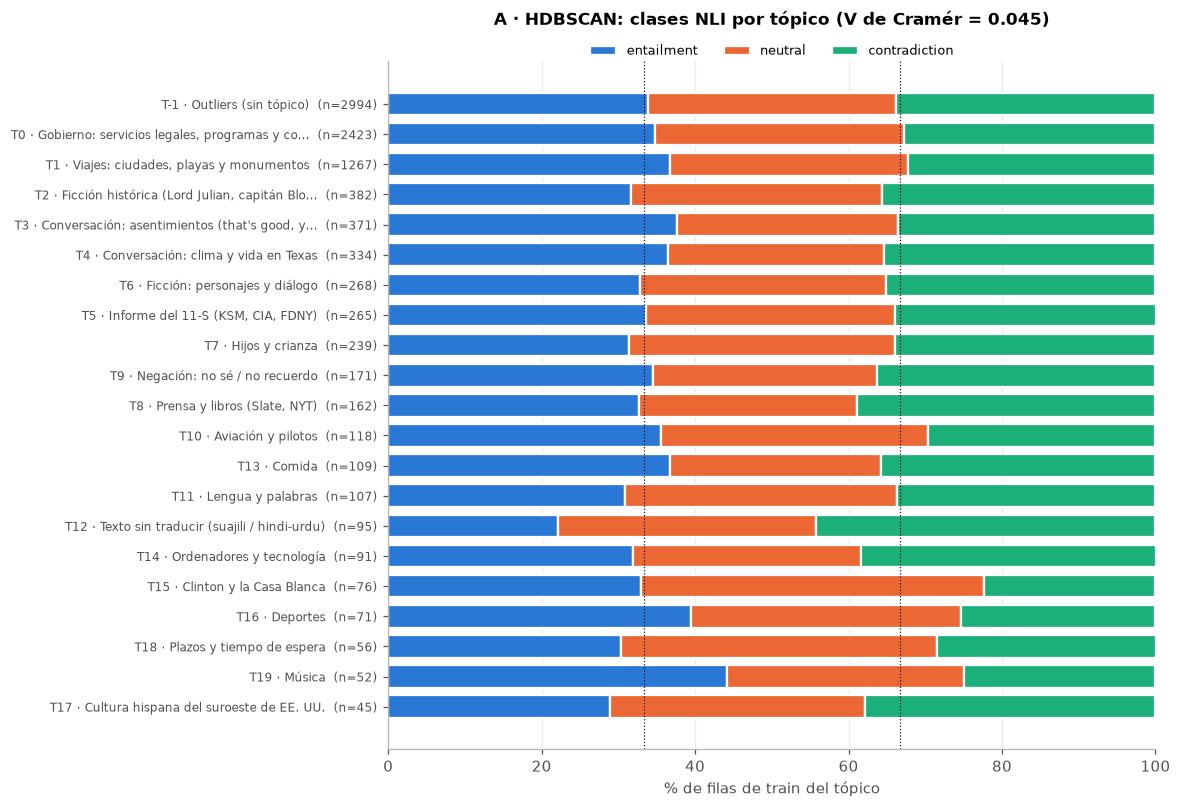

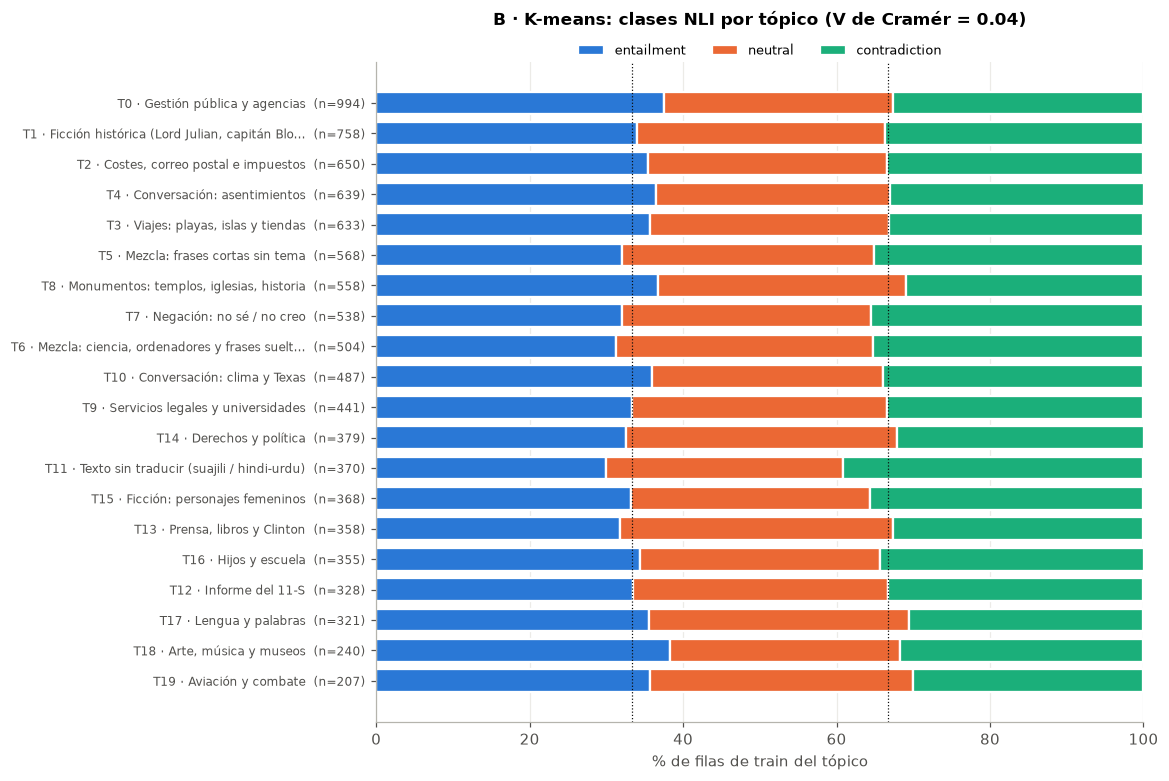

In [20]:
def barra_apilada(tabla, titulo):
    """% de cada clase dentro de cada tópico, con el número de filas en la etiqueta."""
    t = tabla.sort_values("n")
    fig, ax = plt.subplots(figsize=(9, 0.32 * len(t) + 1.4))
    izquierda = np.zeros(len(t))
    for clase in LABELS.values():
        ax.barh(range(len(t)), t[f"{clase} %"], left=izquierda, color=COLOR_CLASE[clase],
                edgecolor="white", linewidth=1.5, height=0.75, label=clase)
        izquierda += t[f"{clase} %"].values
    ax.set_yticks(range(len(t)), [f"T{k} · {corto(nm, 44)}  (n={n})" for k, nm, n in zip(t.index, t.nombre, t.n)], fontsize=8)
    for x in (100 / 3, 200 / 3):                       # líneas de referencia: reparto perfectamente igualado
        ax.axvline(x, color="#0b0b0b", lw=0.8, ls=":")
    ax.set_xlim(0, 100); ax.set_xlabel("% de filas de train del tópico"); ax.grid(axis="y", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.0 + 0.9 / len(t)), ncol=3, fontsize=8.5)
    ax.set_title(titulo, pad=24)
    plt.show()


barra_apilada(tc_hdb, f"A · HDBSCAN: clases NLI por tópico (V de Cramér = {est_hdb['V_Cramer']})")
barra_apilada(tc_km, f"B · K-means: clases NLI por tópico (V de Cramér = {est_km['V_Cramer']})")

Casi todas las barras están cerca del reparto global (~34/32/34 %). En A, χ² = 40,0 con 40 g.l. (p = 0,47) y V = 0,045; en B, χ² = 30,3 con 38 g.l. (p = 0,81) y V = 0,040. No se puede rechazar que la mezcla de clases sea la misma en todos los tópicos, y la relación es despreciable: el tópico no determina la clase.

Las desviaciones visibles están en tópicos pequeños, donde unas pocas filas mueven mucho el porcentaje (por eso se muestra siempre el *n*). Por ejemplo, *Clinton* (n=76) tiene un 45 % de neutral, algo compatible con el azar con ese tamaño. Es lo esperable: para cada premisa se escribieron hipótesis de las tres clases, así que el tema de la premisa no puede predecir la clase.

## 10. ¿Agrupan los tópicos por idioma o por tema?

El corpus original tiene 15 idiomas, así que hay que comprobar que los grupos no son simplemente "los textos en chino", "los textos en árabe"… Se mide sobre las premisas de train:
- **NMI(tópico, idioma):** 0 si el tópico no dice nada del idioma.
- **% de premisas inglesas por tópico**, comparado con el global (43 %). Si un tópico agrupara por idioma, tendría casi todo inglés o casi nada.

In [21]:
base_en = np.mean(lang_tr == "en")   # proporción global de premisas inglesas


def composicion_idioma(top, nombres):
    """Por tópico: tamaño, idioma más frecuente y % de inglés."""
    d = pd.DataFrame({"topic": top, "lang": lang_tr})
    f = d.groupby("topic").lang.agg(n="size", idioma_mas_frecuente=lambda s: s.value_counts().index[0],
                                     pct_idioma_mas_frecuente=lambda s: round(100 * s.value_counts(normalize=True).iloc[0], 1),
                                     pct_ingles=lambda s: round(100 * s.eq("en").mean(), 1))
    f.insert(0, "nombre", [nombres[k] for k in f.index])
    return f


idi_hdb, idi_km = composicion_idioma(top_hdb, NOMBRES_HDB), composicion_idioma(top_km, NOMBRES_KM)
print(f"Premisas inglesas en train: {base_en:.1%} | NMI con el idioma: HDBSCAN {NMI(lang_tr, top_hdb):.3f}, K-means {NMI(lang_tr, top_km):.3f}")
print("A · HDBSCAN"); display(idi_hdb)
print("B · K-means"); display(idi_km)

Premisas inglesas en train: 43.2% | NMI con el idioma: HDBSCAN 0.026, K-means 0.021
A · HDBSCAN


,nombre,n,idioma_mas_frecuente,pct_idioma_mas_frecuente,pct_ingles
topic,,,,,
-1,Outliers (sin tópico),2182,en,43.4,43.4
0,"Gobierno: servicios legales, programas y costes",1762,en,45.1,45.1
1,"Viajes: ciudades, playas y monumentos",859,en,55.1,55.1
2,"Ficción histórica (Lord Julian, capitán Blood)",287,en,36.9,36.9
3,"Conversación: asentimientos (that's good, yes)",254,en,48.8,48.8
4,Conversación: clima y vida en Texas,236,en,50.4,50.4
5,"Informe del 11-S (KSM, CIA, FDNY)",236,en,9.3,9.3
6,Ficción: personajes y diálogo,193,en,50.3,50.3
7,Hijos y crianza,179,en,36.9,36.9


B · K-means


,nombre,n,idioma_mas_frecuente,pct_idioma_mas_frecuente,pct_ingles
topic,,,,,
0,Gestión pública y agencias,701,en,52.5,52.5
1,"Ficción histórica (Lord Julian, capitán Blood)",516,en,51.7,51.7
2,"Costes, correo postal e impuestos",448,en,54.5,54.5
3,"Viajes: playas, islas y tiendas",436,en,53.0,53.0
4,Conversación: asentimientos,424,en,58.3,58.3
5,Mezcla: frases cortas sin tema,420,en,39.8,39.8
6,"Mezcla: ciencia, ordenadores y frases sueltas",401,en,32.9,32.9
7,Negación: no sé / no creo,386,en,41.7,41.7
8,"Monumentos: templos, iglesias, historia",360,en,61.9,61.9


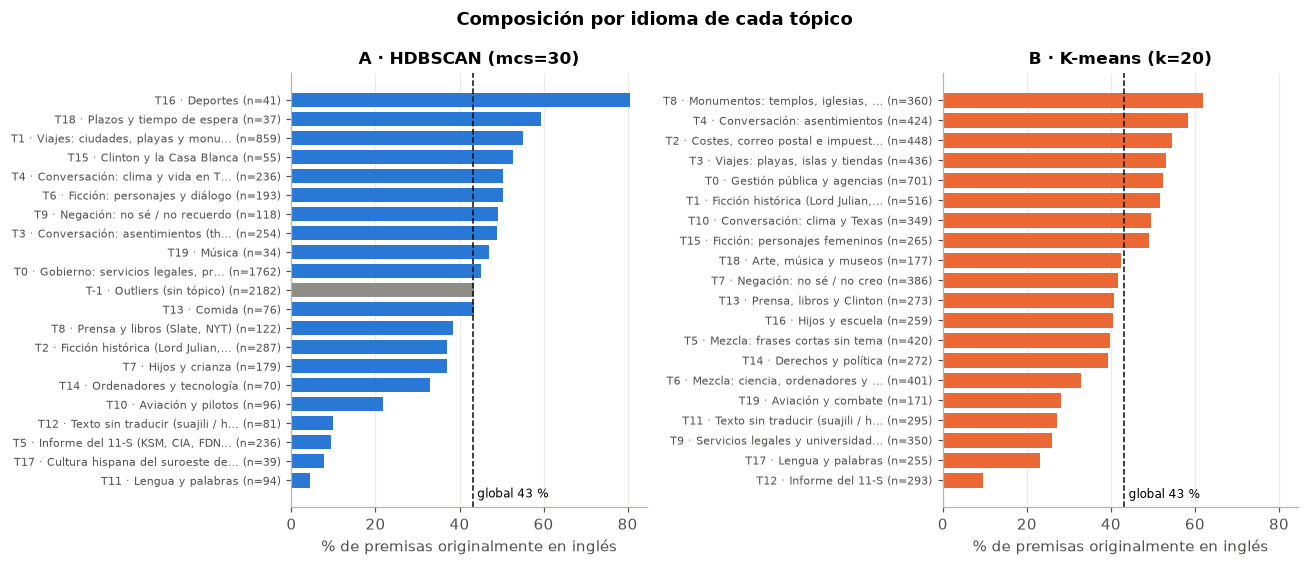

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True)
for ax, tabla, titulo, color in [(axes[0], idi_hdb, f"A · HDBSCAN (mcs={MCS})", PALETA[0]),
                                 (axes[1], idi_km, f"B · K-means (k={K})", PALETA[1])]:
    t = tabla.sort_values("pct_ingles")
    ax.barh(range(len(t)), t.pct_ingles, color=[GRIS if k == -1 else color for k in t.index], height=0.75)
    ax.set_yticks(range(len(t)), [f"T{k} · {corto(nm, 32)} (n={n})" for k, nm, n in zip(t.index, t.nombre, t.n)], fontsize=7.5)
    ax.axvline(100 * base_en, color="#0b0b0b", lw=1, ls="--")
    ax.text(100 * base_en + 1, -0.9, f"global {100 * base_en:.0f} %", fontsize=8)
    ax.set_xlabel("% de premisas originalmente en inglés"); ax.set_title(titulo); ax.grid(axis="y", visible=False)
fig.suptitle("Composición por idioma de cada tópico", fontweight="bold"); fig.tight_layout()
plt.show()

- La NMI entre tópico e idioma es muy baja (0,026 en A y 0,021 en B): los tópicos agrupan por tema. En ningún tópico un idioma distinto del inglés supera el 40 % de los documentos.
- El % de inglés sí cambia entre tópicos (del ~5 % al ~80 %), pero por cómo está construido el dataset: las premisas inglesas y las de los otros idiomas no salen de los mismos textos. Por ejemplo, el informe del 11-S tiene solo un 9 % de premisas inglesas y Deportes (n=41) un 80 %.
- La excepción es el tópico de texto sin traducir, dominado por el suajili, que agrupa por idioma porque esas premisas no llegaron traducidas.
- Además de la traducción, ayuda que el modelo de embeddings sea multilingüe: coloca una frase cerca de su traducción, así que agrupa por significado.

## 11. Conclusiones

In [23]:
display(comparacion.set_index("configuracion").T)
display(pd.DataFrame([{"configuracion": "A · HDBSCAN", **est_hdb}, {"configuracion": "B · K-means", **est_km}]).set_index("configuracion"))

configuracion,A · HDBSCAN mcs=30,B · K-means k=20
n_topicos,20.000,20.000
pct_outliers,30.900,0.000
tam_max,1762.000,701.000
tam_mediana,107.000,349.500
tam_min,34.000,171.000
diversidad_top10,0.895,0.820
NMI_idioma,0.026,0.021
segundos,9.000,9.000


,chi2,gl,p,V_Cramer
configuracion,,,,
A · HDBSCAN,40.0,40,0.469,0.045
B · K-means,30.3,38,0.807,0.040


- **Corpus:** 7.051 premisas de train sin repetir, con texto traducido. Las 2.250 premisas de val reciben su tópico con `transform`.
- **A · HDBSCAN (mcs=30):** 20 tópicos y 31 % de outliers. Tópicos pequeños muy claros (11-S, ficción histórica, Clinton, música, deportes) y un tópico "gobierno" demasiado grande.
- **B · K-means (k=20):** sin outliers y con tamaños más equilibrados. Parte bien el bloque del gobierno, pero crea 2–3 grupos sin tema.
- **Los tópicos son los géneros de MultiNLI** (gobierno, viajes, ficción, teléfono, Slate, 11-S).
- **Jerarquía:** sí la hay. El árbol separa primero lo oral/narrativo de lo escrito/informativo, y los tópicos grandes de HDBSCAN tienen subtópicos claros en K-means (gobierno en 4, viajes en 3).
- **Clases NLI:** relación despreciable (V de Cramér ≈ 0,04). El tema de la premisa no predice la relación entre premisa e hipótesis.
- **Idioma:** NMI ≈ 0,03; los tópicos agrupan por tema. La única excepción es el tópico de texto sin traducir.